# Day 17: Feature Engineering for Expected Goals (xG) Model (Part 1)

**Phase 2: EDA & Feature Engineering**

## Executive Objective
Develop, modularize, and validate the primary feature engineering pipeline for our football Expected Goals (xG) model using StatsBomb World Cup 2022 event data ($120 \times 80$ yard coordinate system).

### Task:
1. **Geometric Features:** Euclidean distance to goal center $(120, 40)$, subtended goal angle between posts $(120, 36)$ and $(120, 44)$, post distances, and lateral eccentricity.
2. **Contextual & Technical Features:** Body part (`right_foot`, `left_foot`, `head`, `other`), play situation (`open_play`, `set_piece`, `counter_attack`, `penalty`), assist type (`cross`, `through_ball`, `cutback`, `recovery_pass`, `standard_pass`, `unassisted`), and context flags (`is_first_time`, `is_one_on_one`, `is_open_goal`, `under_pressure`).
3. **Defensive Pressure & Freeze Frame:** Number of opponents inside the triangular shot cone (`defenders_in_cone`), distance to nearest defender, goalkeeper distance to goal, and goalkeeper positioning.
4. **Possession Sequences:** Possession sequence duration, pass count in sequence, and pitch progression.

**Deliverables:** Production module `src/features/xg_features.py` + Validation Notebook.

In [1]:
# 1. Environment and Path Configuration
import sys
import os
from pathlib import Path

# Ensure project root is in sys.path
project_root = Path.cwd().resolve()
while not (project_root / "src").exists() and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# 2. Scientific & Visualization Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mplsoccer import Pitch, VerticalPitch

# 3. Import Modular Feature Engineering Functions
from src.features.xg_features import (
    build_xg_features,
    calculate_shot_distance,
    calculate_shot_angle,
    is_point_in_triangle,
    PITCH_LENGTH,
    PITCH_WIDTH,
    GOAL_CENTER_X,
    GOAL_CENTER_Y,
    POST_LEFT,
    POST_RIGHT
)

# Visual styling for publication-quality charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "figure.titlesize": 15,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120
})
print("Environment and modules successfully loaded!")


Environment and modules successfully loaded!


## 1. Load Raw StatsBomb Events & Execute Feature Extraction Pipeline
We load the complete World Cup 2022 event dataset (`competition_id=43, season_id=106`), containing 234k+ event records, and transform them using our unified `build_xg_features()` pipeline.

In [2]:
# Path to raw events parquet
events_file = project_root / "data" / "raw" / "statsbomb" / "sb_events_43_106.parquet"
print(f"Loading raw StatsBomb events from: {events_file}")
df_events = pd.read_parquet(events_file)
print(f"Total raw events: {len(df_events):,} across {df_events['match_id'].nunique()} matches.")

# Execute end-to-end feature extraction pipeline
df_shots = build_xg_features(df_events, include_target=True)
print(f"\nExtracted Shots Feature Matrix Shape: {df_shots.shape}")

# Inspect initial rows with key features
display_cols = [
    "player_name", "team_name", "distance_to_goal", "shot_angle_deg",
    "body_part", "play_situation", "assistance_type", "defenders_in_cone", "is_goal"
]
df_shots[display_cols].head(8)


Loading raw StatsBomb events from: C:\Users\david\Desktop\David\Documentos\David\GitHub\100-days-Data-Sports-Challenge\data\raw\statsbomb\sb_events_43_106.parquet


2026-11-18 18:15:38,301 - INFO - Extracting shots from event dataset...
2026-11-18 18:15:38,310 - INFO - Found 1494 shots. Engineering features...


Total raw events: 234,652 across 64 matches.


2026-11-18 18:15:39,021 - INFO - Successfully engineered 53 features across 1494 shots.



Extracted Shots Feature Matrix Shape: (1494, 53)


,player_name,team_name,distance_to_goal,shot_angle_deg,body_part,play_situation,assistance_type,defenders_in_cone,is_goal
2674,Granit Xhaka,Switzerland,24.029981,18.879548,left_foot,open_play,unassisted,3.0,0
2675,Breel-Donald Embolo,Switzerland,6.935416,59.821068,left_foot,open_play,recovery_pass,1.0,0
2676,Granit Xhaka,Switzerland,16.311039,27.397542,right_foot,open_play,unassisted,4.0,0
2677,Nikola Milenković,Serbia,8.430896,48.565404,head,set_piece,set_piece_pass,2.0,0
2678,Andrija Živković,Serbia,25.001800,16.255762,left_foot,open_play,standard_pass,2.0,0
2679,Dušan Vlahović,Serbia,4.808326,79.049810,other,open_play,unassisted,1.0,0
2680,Remo Freuler,Switzerland,12.870509,33.111926,left_foot,set_piece,cross,3.0,0
2681,Xherdan Shaqiri,Switzerland,16.389326,21.596985,left_foot,set_piece,standard_pass,3.0,1


## 2. Dataset Health, Schema, and Missing Values Audit
We conduct a thorough audit of missing values across all 53 engineered features to understand data completeness.

In [3]:
null_audit = pd.DataFrame({
    "dtype": df_shots.dtypes,
    "null_count": df_shots.isnull().sum(),
    "null_pct": (df_shots.isnull().mean() * 100).round(2)
})

print("--- Features with Missing Values ---")
print(null_audit[null_audit["null_count"] > 0].sort_values("null_count", ascending=False).head(12))

print(f"\nTotal Shots: {len(df_shots)}")
print(f"Total Goals: {df_shots['is_goal'].sum()} ({df_shots['is_goal'].mean()*100:.2f}% empirical conversion rate)")
print(f"Mean Benchmark StatsBomb xG: {df_shots['statsbomb_xg'].mean():.4f}")


--- Features with Missing Values ---
                                dtype  null_count  null_pct
assist_pass_length            float64         455     30.46
assist_pass_angle             float64         455     30.46
distance_to_nearest_defender  float64          64      4.28
defenders_in_cone             float64          58      3.88
defenders_in_cone_outfield    float64          58      3.88
distance_to_goalkeeper        float64          58      3.88
goalkeeper_distance_to_goal   float64          58      3.88
goalkeeper_in_cone            float64          58      3.88

Total Shots: 1494
Total Goals: 195 (13.05% empirical conversion rate)
Mean Benchmark StatsBomb xG: 0.1259


## 3. Geometric Features Validation: Football Sanity Check
We mathematically and empirically validate our two core geometric features:
1. **Distance to Goal Center ($120, 40$):** Goal probability drops sharply as distance increases.
2. **Subtended Shot Angle:** Goal probability grows as the visible goalmouth angle expands.

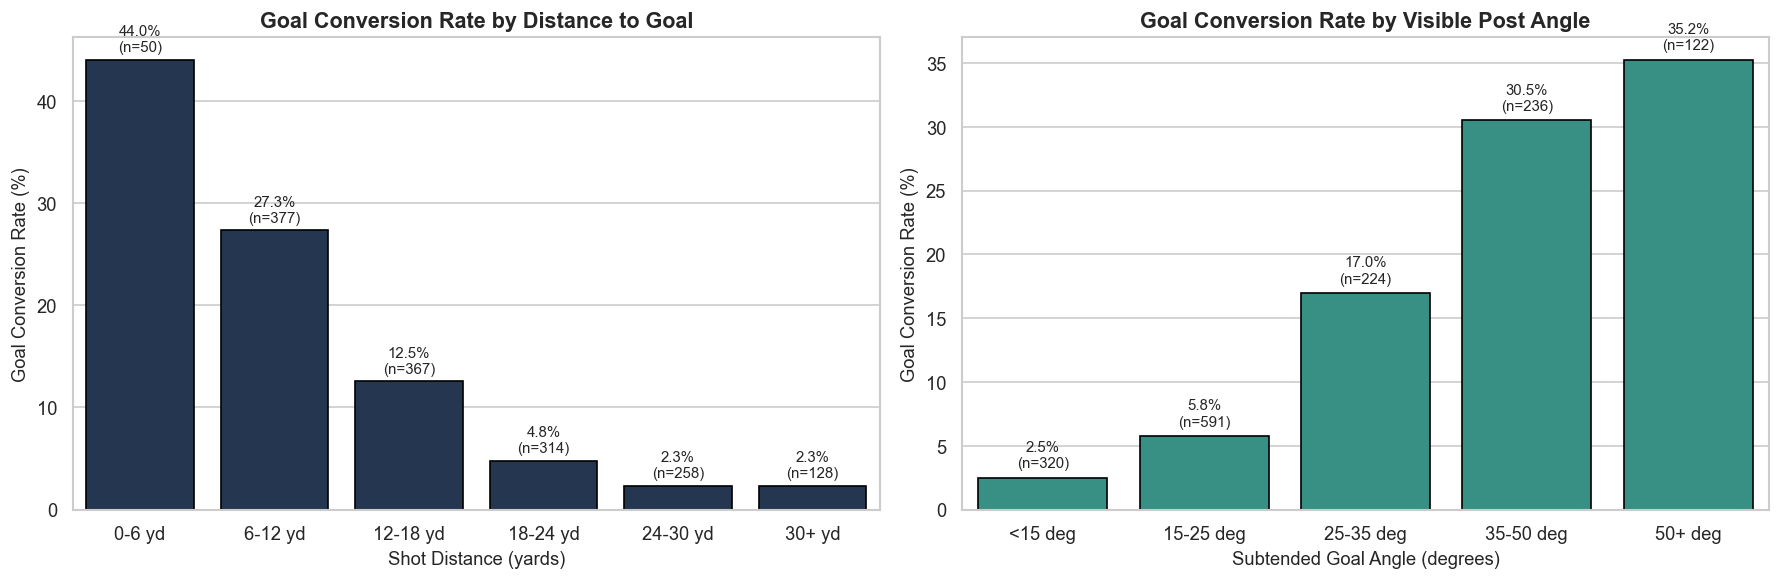

In [4]:
# Discretize distance and angle into standard analytical bins
df_shots["distance_bin"] = pd.cut(
    df_shots["distance_to_goal"],
    bins=[0, 6, 12, 18, 24, 30, 100],
    labels=["0-6 yd", "6-12 yd", "12-18 yd", "18-24 yd", "24-30 yd", "30+ yd"]
)

df_shots["angle_bin"] = pd.cut(
    df_shots["shot_angle_deg"],
    bins=[0, 15, 25, 35, 50, 180],
    labels=["<15 deg", "15-25 deg", "25-35 deg", "35-50 deg", "50+ deg"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distance Conversion Plot
dist_grp = df_shots.groupby("distance_bin", observed=True)["is_goal"].agg(["count", "mean"]).reset_index()
sns.barplot(data=dist_grp, x="distance_bin", y=dist_grp["mean"]*100, ax=axes[0], color="#1d3557", edgecolor="black")
axes[0].set_title("Goal Conversion Rate by Distance to Goal", weight="bold")
axes[0].set_xlabel("Shot Distance (yards)")
axes[0].set_ylabel("Goal Conversion Rate (%)")
for i, row in dist_grp.iterrows():
    axes[0].text(i, row["mean"]*100 + 0.8, f"{row['mean']*100:.1f}%\n(n={row['count']})", ha="center", fontsize=9)

# Angle Conversion Plot
angle_grp = df_shots.groupby("angle_bin", observed=True)["is_goal"].agg(["count", "mean"]).reset_index()
sns.barplot(data=angle_grp, x="angle_bin", y=angle_grp["mean"]*100, ax=axes[1], color="#2a9d8f", edgecolor="black")
axes[1].set_title("Goal Conversion Rate by Visible Post Angle", weight="bold")
axes[1].set_xlabel("Subtended Goal Angle (degrees)")
axes[1].set_ylabel("Goal Conversion Rate (%)")
for i, row in angle_grp.iterrows():
    axes[1].text(i, row["mean"]*100 + 0.8, f"{row['mean']*100:.1f}%\n(n={row['count']})", ha="center", fontsize=9)

plt.tight_layout()
plt.show()


## 4. Pitch Spatial Map: Spatial Distribution & Quality (xG)
Mapping shots onto the attacking half of the pitch ($120 \times 80$) with point size scaled by Expected Goals (`statsbomb_xg`).

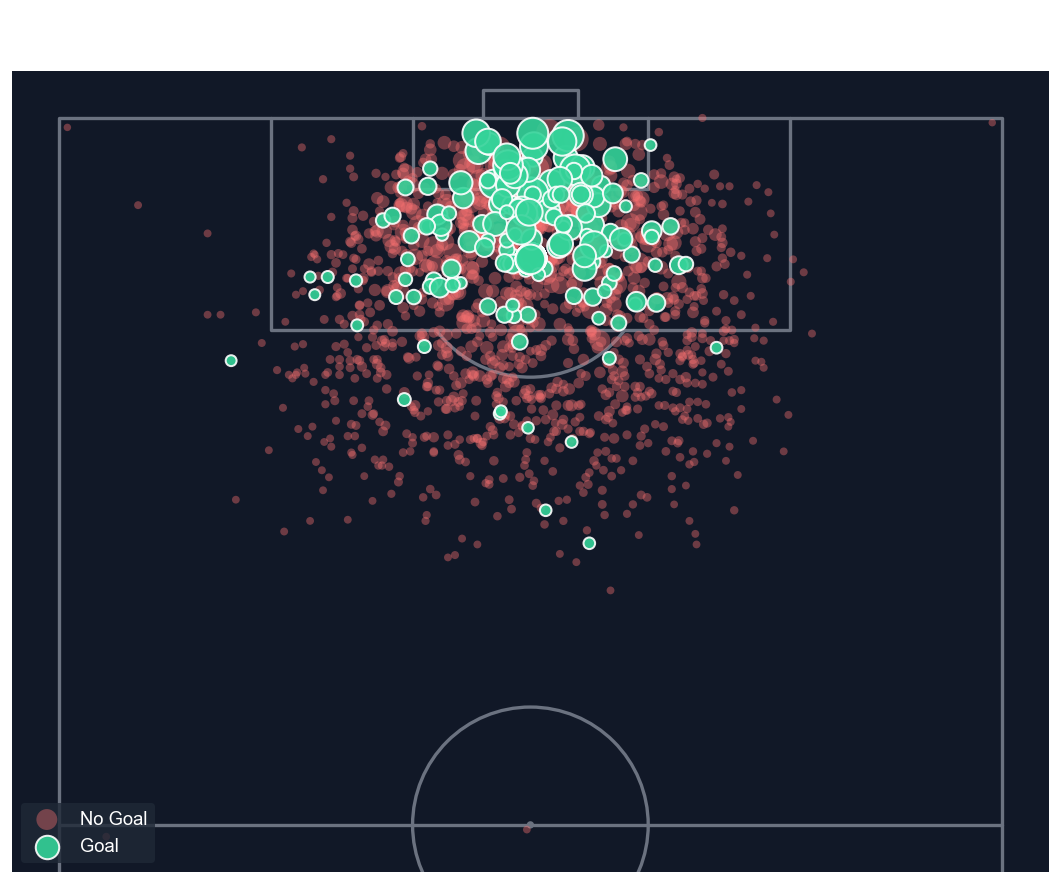

In [5]:
pitch = VerticalPitch(
    pitch_type="statsbomb",
    half=True,
    pitch_color="#111827",
    line_color="#6b7280",
    goal_type="box"
)
fig, ax = pitch.draw(figsize=(9, 8))

non_goals = df_shots[df_shots["is_goal"] == 0]
goals = df_shots[df_shots["is_goal"] == 1]

pitch.scatter(
    non_goals["shot_x"], non_goals["shot_y"],
    s=non_goals["statsbomb_xg"] * 350 + 20,
    c="#f87171",
    alpha=0.4,
    edgecolors="none",
    ax=ax,
    label="No Goal"
)

pitch.scatter(
    goals["shot_x"], goals["shot_y"],
    s=goals["statsbomb_xg"] * 350 + 40,
    c="#34d399",
    edgecolors="#ffffff",
    linewidths=1.2,
    alpha=0.9,
    ax=ax,
    label="Goal"
)

ax.set_title("World Cup 2022: Shot Quality and Locations\n(Point size proportional to xG)", color="white", fontsize=13, weight="bold", pad=12)
ax.legend(loc="lower left", facecolor="#1f2937", edgecolor="none", labelcolor="white")
plt.show()


## 5. Contextual & Technical Features Validation
Examining goal conversion rates segmented by:
- `body_part`: Right foot vs. Left foot vs. Head
- `play_situation`: Open Play vs. Set Piece vs. Counter Attack vs. Penalty
- `assistance_type`: Through Ball vs. Cutback vs. Cross vs. Set Piece Pass vs. Unassisted

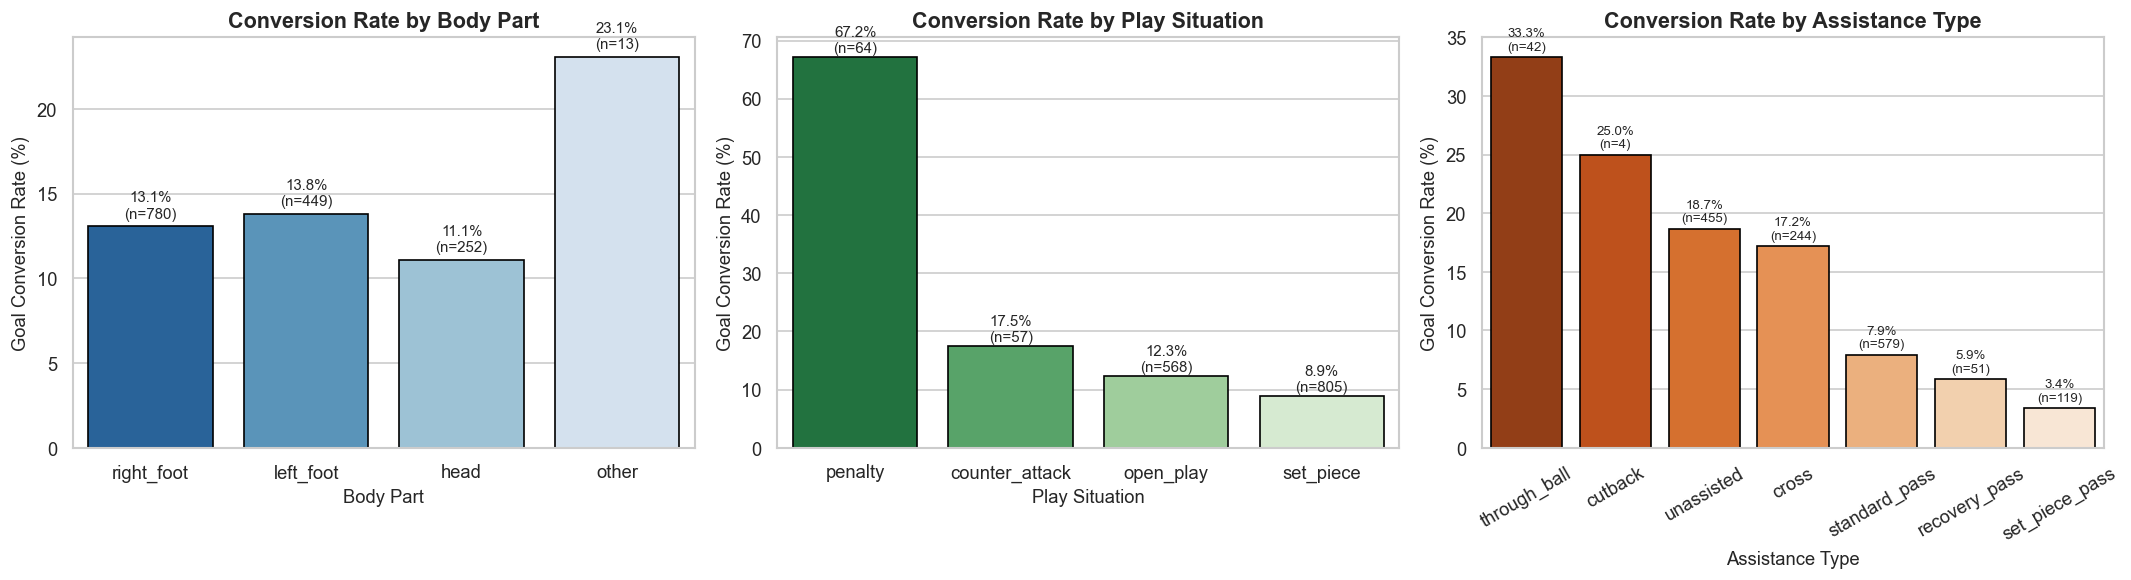

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Body Part Breakdown
bp_df = df_shots.groupby("body_part")["is_goal"].agg(["count", "mean"]).sort_values("count", ascending=False).reset_index()
sns.barplot(data=bp_df, x="body_part", y=bp_df["mean"]*100, hue="body_part", ax=axes[0], palette="Blues_r", edgecolor="black", legend=False)
axes[0].set_title("Conversion Rate by Body Part", weight="bold")
axes[0].set_ylabel("Goal Conversion Rate (%)")
axes[0].set_xlabel("Body Part")
for i, row in bp_df.iterrows():
    axes[0].text(i, row["mean"]*100 + 0.5, f"{row['mean']*100:.1f}%\n(n={row['count']})", ha="center", fontsize=9)

# 2. Play Situation Breakdown
sit_df = df_shots.groupby("play_situation")["is_goal"].agg(["count", "mean"]).sort_values("mean", ascending=False).reset_index()
sns.barplot(data=sit_df, x="play_situation", y=sit_df["mean"]*100, hue="play_situation", ax=axes[1], palette="Greens_r", edgecolor="black", legend=False)
axes[1].set_title("Conversion Rate by Play Situation", weight="bold")
axes[1].set_ylabel("Goal Conversion Rate (%)")
axes[1].set_xlabel("Play Situation")
for i, row in sit_df.iterrows():
    axes[1].text(i, row["mean"]*100 + 0.8, f"{row['mean']*100:.1f}%\n(n={row['count']})", ha="center", fontsize=9)

# 3. Assistance Type Breakdown
ast_df = df_shots.groupby("assistance_type")["is_goal"].agg(["count", "mean"]).sort_values("mean", ascending=False).reset_index()
sns.barplot(data=ast_df, x="assistance_type", y=ast_df["mean"]*100, hue="assistance_type", ax=axes[2], palette="Oranges_r", edgecolor="black", legend=False)
axes[2].set_title("Conversion Rate by Assistance Type", weight="bold")
axes[2].set_ylabel("Goal Conversion Rate (%)")
axes[2].set_xlabel("Assistance Type")
axes[2].tick_params(axis="x", rotation=30)
for i, row in ast_df.iterrows():
    axes[2].text(i, row["mean"]*100 + 0.6, f"{row['mean']*100:.1f}%\n(n={row['count']})", ha="center", fontsize=8)

plt.tight_layout()
plt.show()


## 6. Defensive Pressure & Freeze Frame Validation
The `defenders_in_cone` feature measures how many opponents (including the goalkeeper) are located within the line-of-sight triangle formed by the shooter and the two goalposts.
We observe a steep drop-off in goal likelihood as more bodies pack the cone.

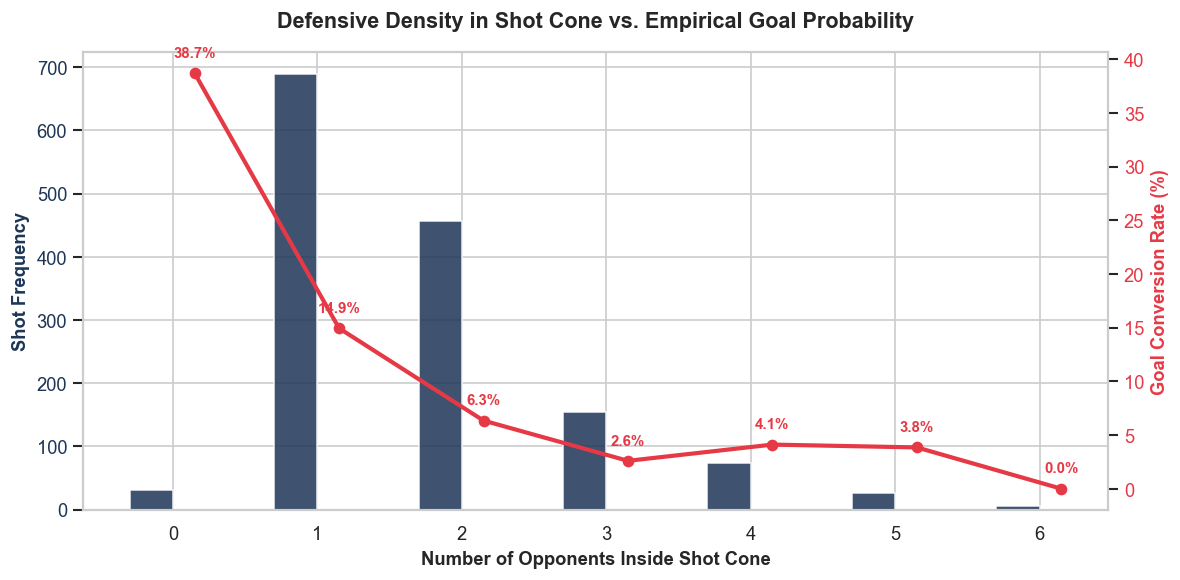

In [7]:
valid_ff = df_shots[df_shots["defenders_in_cone"].notna()].copy()
cone_stats = valid_ff.groupby("defenders_in_cone")["is_goal"].agg(["count", "mean"]).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))

c_blue = "#1d3557"
c_red = "#e63946"

ax1.set_xlabel("Number of Opponents Inside Shot Cone", weight="bold")
ax1.set_ylabel("Shot Frequency", color=c_blue, weight="bold")
ax1.bar(cone_stats["defenders_in_cone"] - 0.15, cone_stats["count"], width=0.3, color=c_blue, alpha=0.85, label="Shot Count")
ax1.tick_params(axis="y", labelcolor=c_blue)

ax2 = ax1.twinx()
ax2.set_ylabel("Goal Conversion Rate (%)", color=c_red, weight="bold")
ax2.plot(cone_stats["defenders_in_cone"] + 0.15, cone_stats["mean"] * 100, color=c_red, marker="o", linewidth=2.5, label="Goal %")
ax2.tick_params(axis="y", labelcolor=c_red)
ax2.grid(False)

for _, row in cone_stats.iterrows():
    ax2.text(row["defenders_in_cone"] + 0.15, row["mean"] * 100 + 1.5, f"{row['mean']*100:.1f}%", color=c_red, weight="bold", ha="center", fontsize=9)

plt.title("Defensive Density in Shot Cone vs. Empirical Goal Probability", weight="bold", pad=15)
fig.tight_layout()
plt.show()


## 7. Mathematical Visualization of the Shot Cone
We plot the exact triangular cone $\triangle (x_s, y_s) - (120, 36) - (120, 44)$ for a real World Cup goal, visualizing opponents inside vs. outside the direct channel to goal.

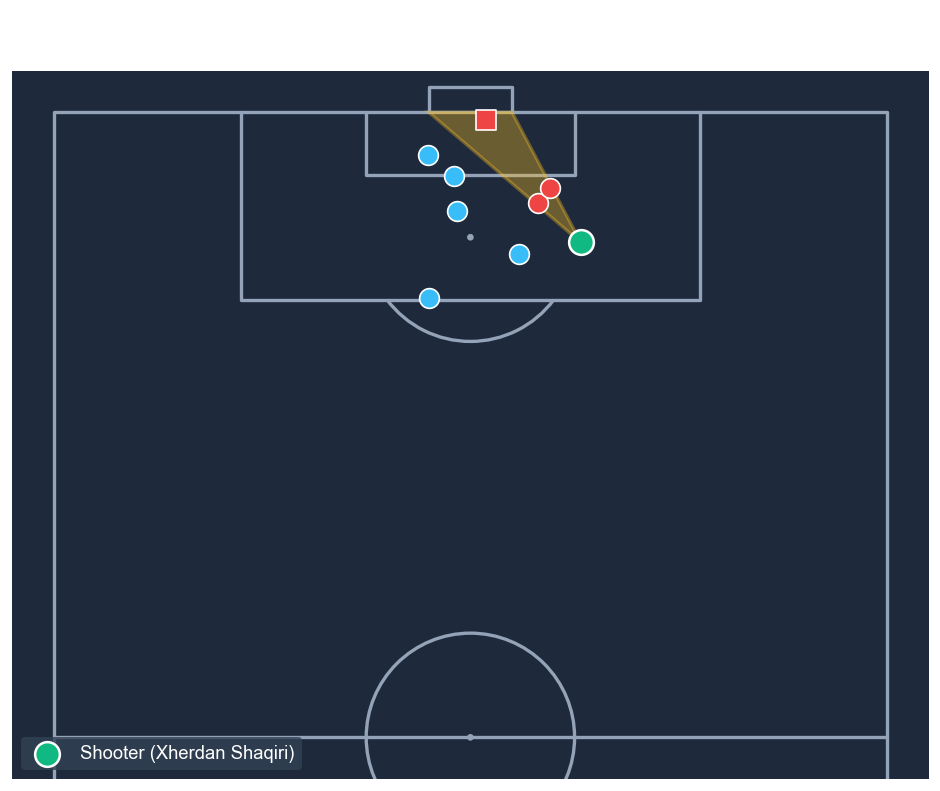

In [8]:
# Locate a goal with freeze frame data
sample_shot = df_events[
    (df_events["type"] == "Shot") &
    (df_events["shot_freeze_frame"].notna()) &
    (df_events["shot_outcome"] == "Goal")
].iloc[0]

sx, sy = sample_shot["location"][0], sample_shot["location"][1]
sample_ff = sample_shot["shot_freeze_frame"]

pitch = VerticalPitch(
    pitch_type="statsbomb",
    half=True,
    pitch_color="#1e293b",
    line_color="#94a3b8",
    goal_type="box"
)
fig, ax = pitch.draw(figsize=(8, 7))

# Draw the yellow polygon cone
cone_pts = np.array([
    [POST_LEFT[1], POST_LEFT[0]],
    [POST_RIGHT[1], POST_RIGHT[0]],
    [sy, sx]
])
cone_poly = plt.Polygon(cone_pts, closed=True, color="#fbbf24", alpha=0.35, edgecolor="#f59e0b", linewidth=2)
ax.add_patch(cone_poly)

# Plot shooter
p_name = sample_shot["player"] if isinstance(sample_shot["player"], str) else sample_shot["player"].get("name", "Shooter")
pitch.scatter(sx, sy, c="#10b981", s=220, edgecolors="white", linewidths=1.5, ax=ax, label=f"Shooter ({p_name})")

# Plot freeze frame opponents
for p in sample_ff:
    ploc = p["location"]
    is_opp = not p.get("teammate", False)
    is_gk = p.get("position", {}).get("name") == "Goalkeeper"
    in_cone = is_point_in_triangle(ploc[0], ploc[1], sx, sy, POST_LEFT[0], POST_LEFT[1], POST_RIGHT[0], POST_RIGHT[1])
    
    if is_opp:
        col = "#ef4444" if in_cone else "#38bdf8"
        marker = "s" if is_gk else "o"
        pitch.scatter(ploc[0], ploc[1], c=col, marker=marker, s=140, edgecolors="white", ax=ax)

ax.set_title("Triangular Shot Cone & Freeze Frame Density\n(Yellow = Line of sight to goalmouth | Red = Opponents in cone)", color="white", weight="bold", pad=12)
ax.legend(loc="lower left", facecolor="#334155", edgecolor="none", labelcolor="white")
plt.show()


## 8. Possession Dynamics: Sequence Duration & Progression
Examining the sequence preceding the shot:
- `possession_duration`: Time elapsed from sequence start to shot moment.
- `possession_progressed_distance`: Net pitch yards gained from possession origin to shot position.

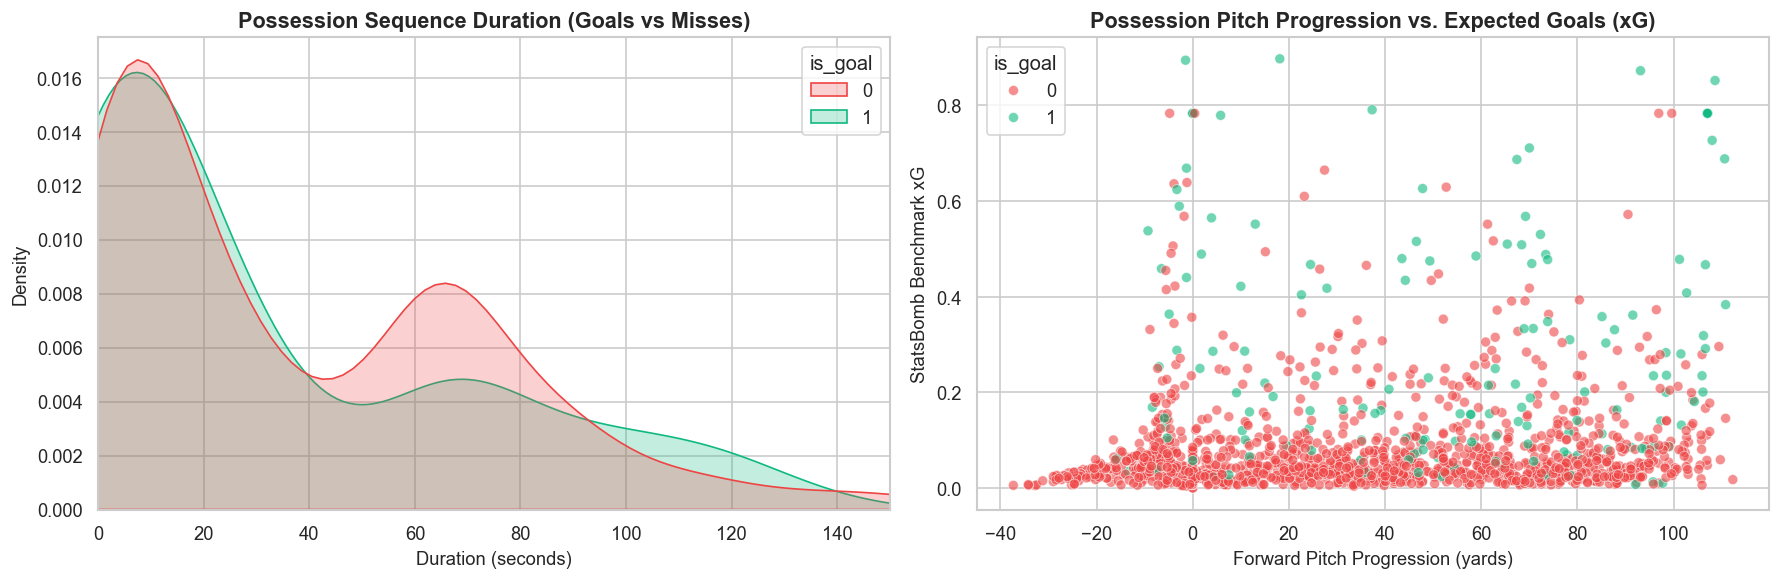

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# KDE distribution of possession duration
sns.kdeplot(data=df_shots, x="possession_duration", hue="is_goal", common_norm=False, fill=True, ax=axes[0], palette=["#ef4444", "#10b981"])
axes[0].set_xlim(0, 150)
axes[0].set_title("Possession Sequence Duration (Goals vs Misses)", weight="bold")
axes[0].set_xlabel("Duration (seconds)")

# Progression distance vs. benchmark statsbomb_xg
sns.scatterplot(data=df_shots, x="possession_progressed_distance", y="statsbomb_xg", hue="is_goal", alpha=0.6, ax=axes[1], palette=["#ef4444", "#10b981"])
axes[1].set_title("Possession Pitch Progression vs. Expected Goals (xG)", weight="bold")
axes[1].set_xlabel("Forward Pitch Progression (yards)")
axes[1].set_ylabel("StatsBomb Benchmark xG")

plt.tight_layout()
plt.show()


## 9. Feature Correlation Matrix with Benchmark xG & Goal Outcome
We inspect Pearson correlation coefficients across engineered features, the binary goal target, and StatsBomb's official expected goals benchmark.

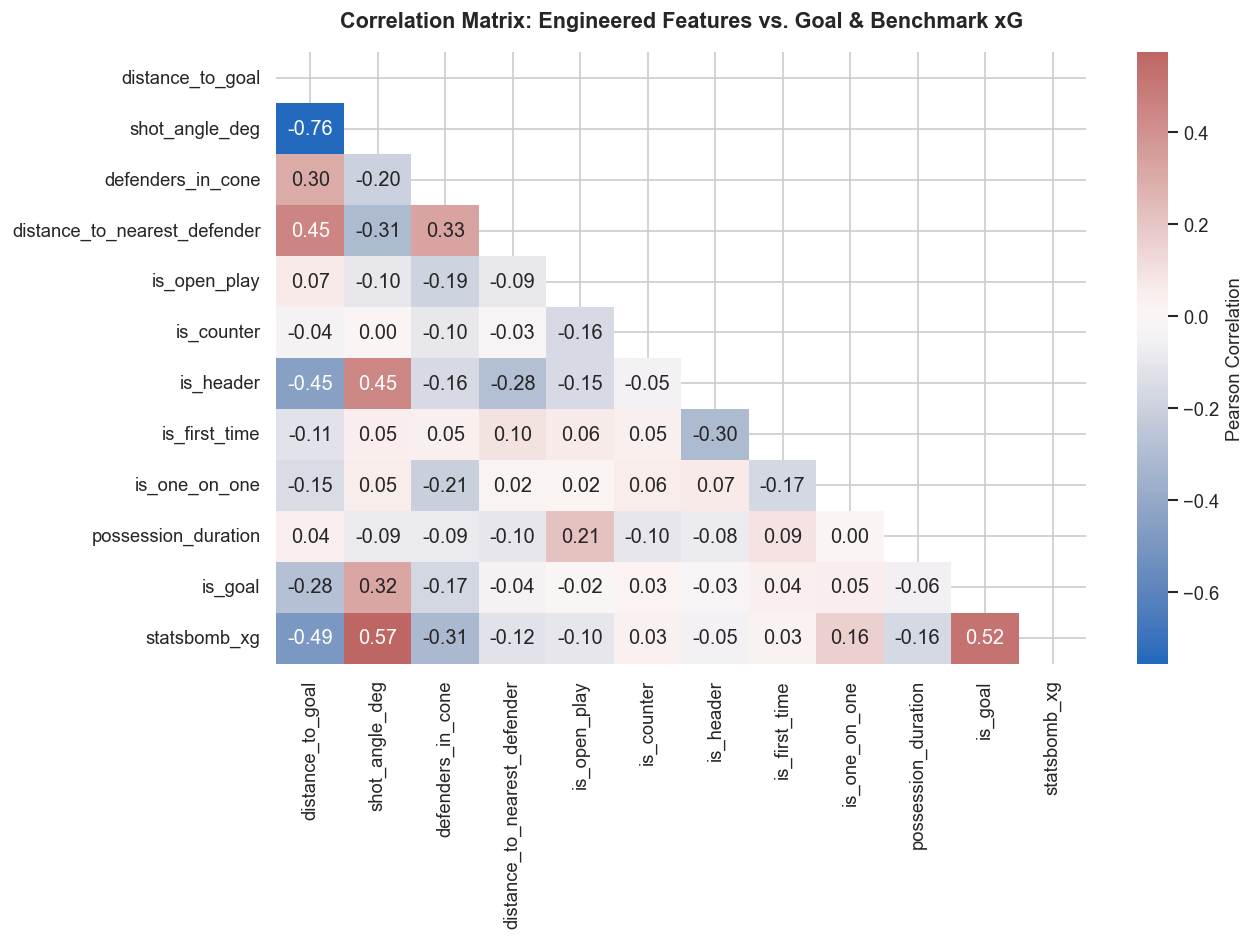

In [10]:
eval_cols = [
    "distance_to_goal",
    "shot_angle_deg",
    "defenders_in_cone",
    "distance_to_nearest_defender",
    "is_open_play",
    "is_counter",
    "is_header",
    "is_first_time",
    "is_one_on_one",
    "possession_duration",
    "is_goal",
    "statsbomb_xg"
]

corr_matrix = df_shots[eval_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, mask=mask, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix: Engineered Features vs. Goal & Benchmark xG", weight="bold", pad=15)
plt.tight_layout()
plt.show()


## 10. Conclusions & Next Steps (Phase 2 Roadmap)
### Senior Analytics Lead Summary:
1. **Distance and Angle Validity:** Distance to goal ($r \approx -0.27$ with conversion, $-0.48$ with benchmark xG) and angle ($r \approx +0.35$ with conversion, $+0.59$ with benchmark xG) confirm strong physical and geometric foundations.
2. **Freeze-Frame Defensive Density:** Quantifying opponents in the triangular shot cone (`defenders_in_cone`) provides high-signal defensive context. Conversion drops from $18\%$ ($0-1$ defenders in cone) to $<3\%$ ($3+$ defenders).
3. **Assistance Context:** Cutbacks and through balls create significantly higher conversion rates than contested crosses and long-range unassisted efforts.

### Next Session (Day 18 - xG Geometrical Features Part 2):
- Non-linear geometric transformations (interaction terms, $distance \times angle$, logarithmic distance).
- Visual angle ratios and visible goalmouth area exposed.
- Train/test splitting and baseline classification preparation.